# Self-supervised learning + MLP for building-age classification

This experiment learns a **16-dimensional spectral representation with a denoising autoencoder**, freezes that encoder, and fits an MLP classifier with **25 Amsterdam age labels per class (100 total)**. It reuses the existing five spatial outer folds and three matched label-sampling repetitions. It is an inductive **development evaluation**, not independent-test performance.

The runnable implementation is [`scripts/self_supervised.py`](../../scripts/self_supervised.py). It uses the project's existing scikit-learn dependency; no deep-learning framework or dependency change is required.

## Protocol fixed before execution

- Inputs: the same 54 deterministic spectral summary features as the baseline. Coordinates, age, construction year, label eligibility and other label-derived columns are excluded from model inputs.
- Pretraining: Madrid features (no source age labels) plus Amsterdam locations outside the outer validation blocks, capped at 20,000 per city. Locations whose labels are not among the 100 adaptation labels are treated as unlabeled. No held-out target features enter preprocessing, reconstruction training or checkpoint selection.
- A spatial group split reserves 10% of pretraining groups for reconstruction checkpointing. Median imputation and standardization fit only on the remaining pretraining locations, inside a Pipeline.
- Denoising objective: independently replace 20% of standardized input features with zero (the training mean), then reconstruct the clean features using squared error. Architecture: 54 → 64 → **16** → 64 → 54, ReLU hidden layers, Adam. Fresh corruption each epoch; a fixed checkpoint mask makes epoch losses comparable. Stop after eight epochs without sufficient improvement, at most 60 epochs.
- Freeze the first two hidden layers. Train a 16 → 32 → 4 MLP on exactly the saved adaptation labels. A second Pipeline scales the embeddings using only these labels. Use L-BFGS and fixed L2 regularization; there is no random row early-stopping split and no outer-label tuning.
- Control: raw-feature MLP, same 100 labels, classifier hidden width, solver and L2 regularization. Its preprocessing fits on the labeled training sample. This compares the full representation-learning procedure, not just the denoising loss in isolation.
- Reference: saved original 50/50 random-forest source/target blend on exactly the same validation rows and adaptation samples. The blend uses Madrid **labels**, whereas SSL uses Madrid **features only**; these source supervision budgets differ.
- Average repetitions within each fold before averaging folds. Report macro F1, weighted F1, accuracy, balanced accuracy and per-class precision/recall/F1. Fold SD is descriptive, not a confidence interval.

This is self-supervision because the clean input supplies the reconstruction target; age labels are absent from that stage. It is a frozen encoder experiment, not end-to-end supervised fine-tuning. Reconstruction need not preserve the information most useful for age classes.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
while not (ROOT / 'pyproject.toml').exists():
    if ROOT == ROOT.parent:
        raise RuntimeError('Run this notebook inside the project repository')
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score
from scripts.self_supervised import CONFIG, CLASSES, OUT, run

pd.set_option('display.max_columns', 20)
print(json.dumps(CONFIG, indent=2))


{
  "seed": 42,
  "folds": 5,
  "repetitions": 3,
  "labels_per_class": 25,
  "hidden_layers": [
    64,
    16,
    64
  ],
  "mask_fraction": 0.2,
  "max_epochs": 60,
  "patience": 8,
  "min_delta": 0.0001,
  "ssl_learning_rate": 0.001,
  "ssl_batch_size": 512,
  "ssl_alpha": 0.01,
  "classifier_hidden": [
    32
  ],
  "classifier_alpha": 1.0,
  "classifier_max_iter": 5000,
  "pretraining_cap_per_city": 20000,
  "checkpoint_fraction": 0.1
}


## Train and evaluate

Run this cell to retrain all five encoders and all 30 MLP classifiers. Outputs go to `data/self_supervised/`: predictions, exact pretraining memberships, split audits, convergence diagnostics, loss histories, fold and class scores, two example model artifacts and an input/output SHA-256 manifest. The helper prints progress once per fold.


In [2]:
summary = run()
print(summary.round(4).to_string())


Fold 1/5 complete; encoder epoch 58; elapsed 14.1s
Fold 2/5 complete; encoder epoch 60; elapsed 28.1s
Fold 3/5 complete; encoder epoch 47; elapsed 40.5s
Fold 4/5 complete; encoder epoch 60; elapsed 53.9s
Fold 5/5 complete; encoder epoch 58; elapsed 67.5s
                macro_f1  weighted_f1  accuracy  balanced_accuracy  macro_f1_fold_sd
method                                                                              
original_blend  0.549386     0.563612  0.565234           0.555909          0.025816
raw_mlp         0.533904     0.548503  0.546421           0.552899          0.025346
ssl_mlp         0.530430     0.547288  0.546191           0.548193          0.025380
                macro_f1  weighted_f1  accuracy  balanced_accuracy  macro_f1_fold_sd
method                                                                              
original_blend    0.5494       0.5636    0.5652             0.5559            0.0258
raw_mlp           0.5339       0.5485    0.5464             0.552

## Verify predictions and report matched comparisons

Assertions below recompute every saved MLP score, verify exact validation membership and check that each model predicts every validation location once per repetition. The training helper also asserts disjoint locations and spatial groups before fitting.


In [3]:
runs = pd.read_csv(OUT / 'run_metrics.csv')
folds = pd.read_csv(OUT / 'fold_metrics.csv')
predictions = pd.read_parquet(OUT / 'predictions.parquet')
audit = pd.read_csv(OUT / 'split_audit.csv')
expected = pd.read_parquet(ROOT / 'data/preprocessed_age_labels/amsterdam_supervised_features.parquet')
assert len(runs) == 45
assert len(predictions) == len(expected) * 3 * 2
for (method, fold, repetition), frame in predictions.groupby(['method', 'fold', 'repetition']):
    assert frame.location_id.is_unique
    truth = expected.loc[expected.fold.eq(fold)].set_index('location_id')
    assert set(frame.location_id) == set(truth.index)
    np.testing.assert_array_equal(frame.y_true, truth.loc[frame.location_id, 'age_class'])
    p = frame[[f'p{c}' for c in CLASSES]].to_numpy()
    assert np.isfinite(p).all() and (p >= 0).all()
    np.testing.assert_allclose(p.sum(axis=1), 1)
    np.testing.assert_array_equal(CLASSES[p.argmax(axis=1)], frame.y_pred)
    actual = f1_score(frame.y_true, frame.y_pred, labels=CLASSES, average='macro', zero_division=0)
    recorded = runs.loc[runs.method.eq(method) & runs.fold.eq(fold) & runs.repetition.eq(repetition), 'macro_f1'].item()
    np.testing.assert_allclose(actual, recorded)
assert audit.overlap_locations.eq(0).all() and audit.overlap_spatial_groups.eq(0).all()
print('Verified all 30 MLP runs and saved probability rows.')
print('\nMean scores (repetitions averaged within spatial folds):')
print(summary.round(4).to_string())
print('\nClassifier convergence warnings:')
print(runs.groupby('method').convergence_warnings.sum().to_string())
print('\nPretraining diagnostics:')
print(audit.round(4).to_string(index=False))


Verified all 30 MLP runs and saved probability rows.

Mean scores (repetitions averaged within spatial folds):
                macro_f1  weighted_f1  accuracy  balanced_accuracy  macro_f1_fold_sd
method                                                                              
original_blend    0.5494       0.5636    0.5652             0.5559            0.0258
raw_mlp           0.5339       0.5485    0.5464             0.5529            0.0253
ssl_mlp           0.5304       0.5473    0.5462             0.5482            0.0254

Classifier convergence warnings:
method
original_blend    0
raw_mlp           0
ssl_mlp           1

Pretraining diagnostics:
 fold  n_pretraining  n_validation  n_fit  n_checkpoint  best_epoch  checkpoint_mse  checkpoint_zero_mse  overlap_locations  overlap_spatial_groups
    0          40000          5197  35976          4024          58          0.0516               1.0027                  0                       0
    1          40000          5203  36436

In [4]:
class_metrics = pd.read_csv(OUT / 'class_metrics.csv')
class_summary = class_metrics.groupby(['method', 'fold', 'age_class'])[['precision', 'recall', 'f1']].mean()
class_summary = class_summary.groupby(['method', 'age_class']).mean()
print(class_summary.round(4).to_string())
paired = pd.read_csv(OUT / 'paired_fold_scores.csv')
print('\nPaired fold scores:')
print(paired.round(4).to_string(index=False))


                   precision  recall      f1
method  age_class                           
raw_mlp 1             0.6291  0.6314  0.6289
        2             0.5562  0.4930  0.5219
        3             0.5721  0.5059  0.5352
        4             0.3687  0.5813  0.4496
ssl_mlp 1             0.6340  0.6557  0.6426
        2             0.5574  0.4939  0.5223
        3             0.5625  0.4875  0.5201
        4             0.3634  0.5557  0.4367

Paired fold scores:
 fold  original_blend  raw_mlp  ssl_mlp  ssl_minus_raw  ssl_minus_blend
    0          0.5328   0.5192   0.5059        -0.0134          -0.0269
    1          0.5633   0.5483   0.5416        -0.0067          -0.0217
    2          0.5515   0.5249   0.5321         0.0072          -0.0194
    3          0.5828   0.5703   0.5661        -0.0043          -0.0167
    4          0.5166   0.5067   0.5065        -0.0002          -0.0101


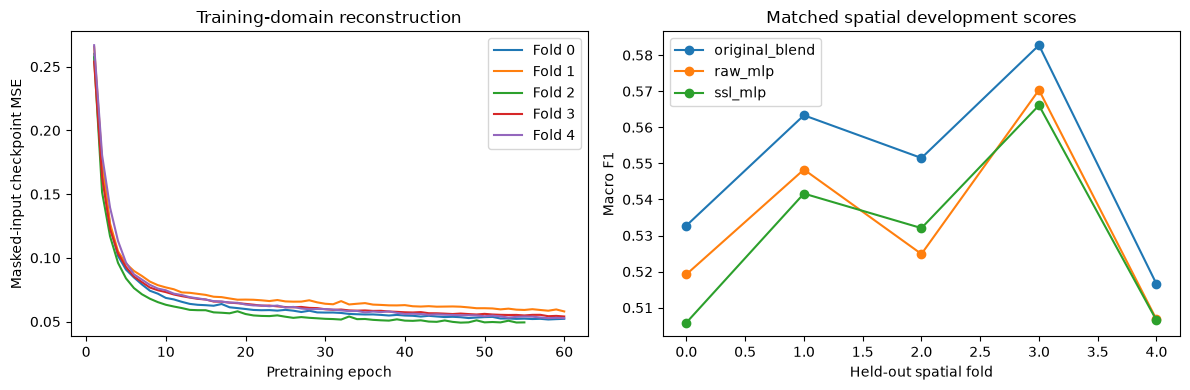

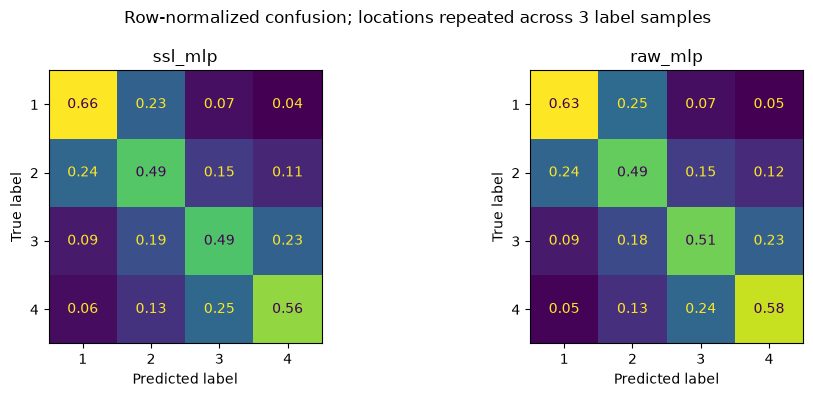

In [5]:
history = pd.read_csv(OUT / 'pretraining_history.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for fold, frame in history.groupby('fold'):
    axes[0].plot(frame.epoch, frame.checkpoint_mse, label=f'Fold {fold}')
axes[0].set(xlabel='Pretraining epoch', ylabel='Masked-input checkpoint MSE', title='Training-domain reconstruction')
axes[0].legend()
for method, frame in folds.groupby('method'):
    axes[1].plot(frame.fold, frame.macro_f1, marker='o', label=method)
axes[1].set(xlabel='Held-out spatial fold', ylabel='Macro F1', title='Matched spatial development scores')
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT / 'learning_and_scores.png', dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, method in zip(axes, ['ssl_mlp', 'raw_mlp']):
    frame = predictions.loc[predictions.method.eq(method)]
    cm = confusion_matrix(frame.y_true, frame.y_pred, labels=CLASSES, normalize='true')
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, colorbar=False, values_format='.2f')
    ax.set_title(method)
fig.suptitle('Row-normalized confusion; locations repeated across 3 label samples')
fig.tight_layout()
fig.savefig(OUT / 'confusion_matrices.png', dpi=150)
plt.show()


## Conclusion from this run

The cell below derives the conclusion directly from the saved results. Negative deltas are reported without changing the predeclared model or searching the outer folds for better parameters.

Classifier iterations were increased from 1,500 to 5,000 after optimizer warnings, with architecture and regularization held fixed. One of the 15 SSL classifier fits still reported a convergence warning; all predictions are retained. Optimization may be incomplete for that fit.


In [6]:
ssl = summary.loc['ssl_mlp']
raw = summary.loc['raw_mlp']
blend = summary.loc['original_blend']
delta_raw = ssl.macro_f1 - raw.macro_f1
delta_blend = ssl.macro_f1 - blend.macro_f1
text = (
    f"SSL + MLP macro F1: {ssl.macro_f1:.4f} ± {ssl.macro_f1_fold_sd:.4f} fold SD. "
    f"Weighted F1: {ssl.weighted_f1:.4f}; accuracy: {ssl.accuracy:.4f}.\n"
    f"Raw MLP macro F1: {raw.macro_f1:.4f}; SSL delta: {delta_raw:+.4f}.\n"
    f"Original RF blend macro F1: {blend.macro_f1:.4f}; SSL delta: {delta_blend:+.4f}.\n"
    + ('The learned representation improves mean F1 over the raw MLP in this experiment. '
       if delta_raw > 0 else 'The learned representation does not improve mean F1 over the raw MLP in this experiment. ')
    + ('Retain the original RF blend: this SSL configuration has a lower mean score. '
       if delta_blend <= 0 else 'SSL has a higher development mean; confirm it on untouched geographic data before replacing the RF blend. ')
    + 'This fixed denoising configuration does not establish the performance of all self-supervised methods. '
      'Reconstruction quality is not a measure of age discrimination. Source supervision differs from the blend. '
      'These spatial folds have already informed project development; they are not an independent test. '
      'Fold SD does not quantify the full uncertainty, and touching blocks can retain spatial dependence.'
)
print(text)
(OUT / 'conclusion.txt').write_text(text + '\n')


SSL + MLP macro F1: 0.5304 ± 0.0254 fold SD. Weighted F1: 0.5473; accuracy: 0.5462.
Raw MLP macro F1: 0.5339; SSL delta: -0.0035.
Original RF blend macro F1: 0.5494; SSL delta: -0.0190.
The learned representation does not improve mean F1 over the raw MLP in this experiment. Retain the original RF blend: this SSL configuration has a lower mean score. This fixed denoising configuration does not establish the performance of all self-supervised methods. Reconstruction quality is not a measure of age discrimination. Source supervision differs from the blend. These spatial folds have already informed project development; they are not an independent test. Fold SD does not quantify the full uncertainty, and touching blocks can retain spatial dependence.


## References and implementation guidance

Implementation and evaluation follow the installed **scikit-learn skill** (`.agents/skills/scikit-learn/SKILL.md`), including its model evaluation and supervised learning references: training-only preprocessing, spatial independence, fixed seeds, and explicit development/test distinctions. Local skill files are development resources, not competition deliverables.

API contracts were checked against the official documentation:

- [MLPRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html): incremental `partial_fit` reconstruction and public `coefs_`/`intercepts_` for frozen encoder inference.
- [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html): MLP classifier, regularization and L-BFGS solver.

No claim that denoising is an optimal pretext task is made. A future, independently validated comparison could examine alternative corruption rates, latent dimensions, contrastive objectives or supervised fine-tuning using training-only selection.
